Note: For each question in this notebook, my answer is written directly below it.


# Learning from mutlimodal input



## The goal of the TP

The goal is to reproduce results form this paper

 Vong et al. (2024). **Grounded language acquisition through the eyes and ears of a single child**. *Science*, 383,504-511 [link](https://openreview.net/pdf/27cf4cba6bd5d6594b40aa340092bbce7b86b3dc.pdf)

Specicfially, we ould like to reproduce this graph, focusing on CLIP and CVCL:

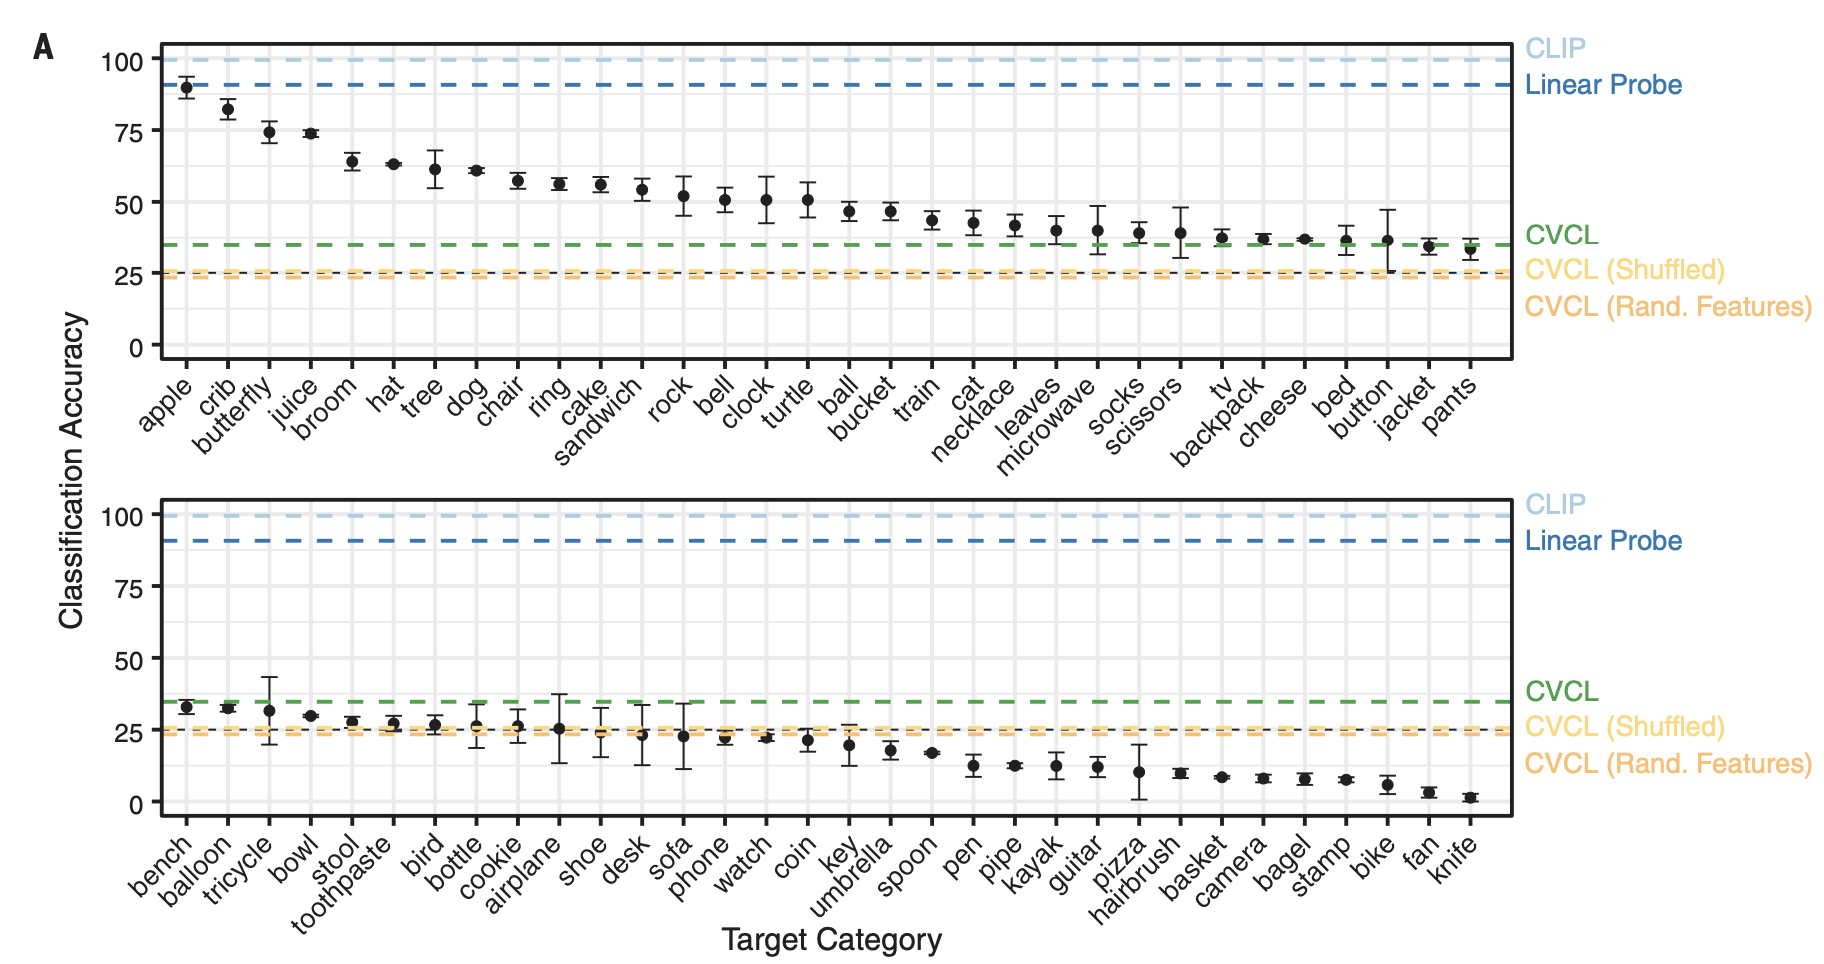

**Question 1:**
Based on your reseach about CLIP, define what it is and explain, in your own words, how it is trained. Keep your explanation concise.

def: it is a vision-language model that is introduced by openai that learns to link images to text using the whole internet as a data set.

training: from its name "Contrastive Language–Image Pre-training" it is trained by seeing enormous number of images and texts aligned with them(labeled) and then comparing those representations by giving right pairs higher similarity than wrong pairs.



**Question 2:**
According to the paper by Vong et al., what are the key differences between CLIP and CVCL?

Both has the same priniciple but different dataset and goal: CLIP has more than 400 million web images-text pairs where as CVCL has 61 hours of recordings from one child. wrt goals: CLIP learns transferable image–text representations	where as CVCL investigate grounded word learning from a child's experience.

**Question 3:**
In the figure above, why do the image recognition scores for CLIP achieve near-perfect accuracy (close to 100%) for various objects, while CVCL scores are noticeably lower? Provide a brief explanation.

answer: the reason is in the way of learning: CLIP learn linking images that are labeled with text, where as CVCL model learn linking images with noisy data(transcript). Also the variety and the size of data differ, with CLIP the data is more than 400 million web images giving it more knowledge for different types of the same object.

**Note:** For this TP, we will attempt to reproduce the results using a different dataset than the one used in the paper. The reason for this is that the dataset in the paper is private and not publicly available.

You can find the dataset we will use in the following folder. To use it in your code, ensure you copy the folder to your Google Drive under the same name.



https://drive.google.com/drive/folders/1dfUgiMe05ka2Ys3nhvom4mFcCtRzaelE?usp=sharing

Next mount your drive usig this code:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

image_dir = "/content/drive/MyDrive/my_images/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Below is the list of images in our dataset:

In [ ]:
import os

labels = [os.path.splitext(f)[0] for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Print the list of labels
print("Available labels in the dataset:")
print(labels)

Available labels in the dataset:
['spoon', 'hat', 'apple', 'shoe', 'ball', 'fork', 'cookie', 'banana', 'key', 'car', 'airplane', 'chair', 'stroller', 'cow']


## CLIP

We start with CLIP

In [ ]:
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-_9_fsb0t
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-_9_fsb0t
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done


In [ ]:
import clip
import torch
from torchvision import transforms
from PIL import Image
import itertools
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.cuda.is_available())


True


In [ ]:
# --- FIX: Disable PyTorch's weights_only restriction globally ---
_original_torch_load = torch.load  # keep a copy of the original

def torch_load_no_restrict(*args, **kwargs):
    # force weights_only=False for all torch.load() calls
    kwargs["weights_only"] = False
    return _original_torch_load(*args, **kwargs)

torch.load = torch_load_no_restrict
#

**Question 3:**
Read the code below and explain, in simple terms, what happens at STEP 1, STEP 2, and STEP 3.





step1: we get the path of an image (in this cas we chose cow as the target label), then we convert the colors of this image to RGB then.resize and normalize the image, after that we added a batch dimension (add 1 to the beginning of the tensorand )then we move the tokenization to CPU/GPU.

step2: we create the embddings of the image and of the text using the clip model

step3: we calculate the similarity between them using dot product.

**Question 4:**
Experiment by changing the target label provided to the model and the alternative images the model can choose from. Briefly describe your observations in one or two sentences.

By changing the target labels and alternative images, I observed that CLIP can often correctly match a word to its corresponding image, even when the other image shows a different object.

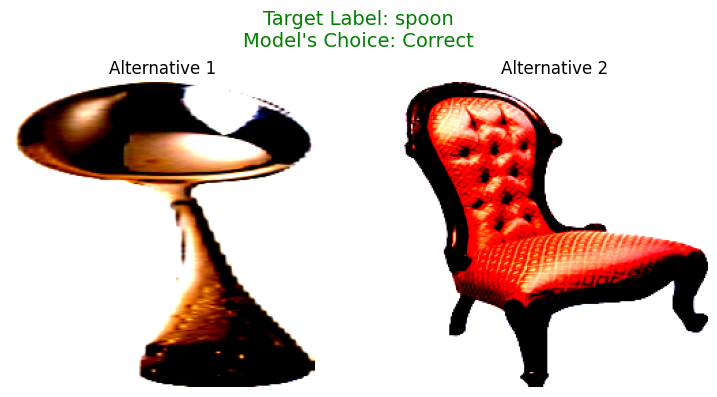

In [ ]:
# Load CLIP model
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)

# Define image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create a dictionary of label to image path
image_paths = {os.path.splitext(f)[0]: os.path.join(image_dir, f)
               for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))}

# Specify the target label and alternative images
list_of_iamges= ['spoon', 'hat', 'apple', 'shoe', 'ball', 'fork',
 'cookie', 'banana', 'key', 'car', 'airplane', 'chair', 'stroller', 'cow']

label = "spoon"  # Target label
images = ["spoon", "chair"]  # Alternatives (one matches the label, the other is a distractor)

# Ensure the label and images exist in the dataset
if label not in image_paths or any(img not in image_paths for img in images):
    print("Error: One or more labels do not exist in the dataset.")

# (STEP 1) Preprocess the target image and distractors
target_image_path = image_paths[label]
target_image = transform(Image.open(target_image_path).convert("RGB")).unsqueeze(0).to(device)

distractor_image_paths = [image_paths[img] for img in images]
distractor_images = [transform(Image.open(path).convert("RGB")).unsqueeze(0).to(device) for path in distractor_image_paths]

# Combine all images for evaluation
all_images = torch.cat([target_image] + distractor_images, dim=0)

# Tokenize the text inputs
text_inputs = clip.tokenize([label] + images).to(device)

# (STEP 2) Encode images and text using CLIP
with torch.no_grad():
    image_features = clip_model.encode_image(all_images)
    text_features = clip_model.encode_text(text_inputs)

    # (STEP 3) Calculate similarity scores
    logits_per_image = image_features @ text_features.T


# Determine the chosen image index
chosen_idx = logits_per_image[1:, 0].argmax().item() + 1  # Get the chosen index (adjust for target being 0)

########
# This code is only for Display:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Show first alternative
axes[0].imshow(distractor_images[0].squeeze().permute(1, 2, 0).cpu().numpy())
axes[0].axis("off")
axes[0].set_title("Alternative 1")

# Show second alternative
axes[1].imshow(distractor_images[1].squeeze().permute(1, 2, 0).cpu().numpy())
axes[1].axis("off")
axes[1].set_title("Alternative 2")

# Display the target label and correctness of the choice
plt.suptitle(f"Target Label: {label}\nModel's Choice: {'Correct' if chosen_idx == 1 else 'Incorrect'}", fontsize=14, color="green" if chosen_idx == 1 else "red")

plt.tight_layout()
plt.show()

**Question 5:**
Briefly describe the main objective of the code below in a couple of sentences.

it evaluates how accurately CLIP matches image labels to their corresponding images. For each target label, it compares the target image against every other image as a distractor, checks whether CLIP correctly identifies the target, and calculates the classification accuracy for each label as a percentage.

**Question 6:**
Analyze and provide your comments on the results.

CLIP achieved 100% accuracy for 13 labels but only 69.23% for the spoon. I thought this confusion is caused by like misclassifying the spoon with a fork or something with similar traits, so i decided to see the reason behind this and i wrote a code that will show exactly which distractor labels caused CLIP to misclassify the spoon, and the result was :shoe, ball, car and key. this didn't give me any conclusion about the reason behind why spoon got just 69.23% where are the others got 100 % accuracy.

In [ ]:

# Load CLIP model
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)

# Image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Load images and create a dictionary of label to image path
image_paths = {os.path.splitext(f)[0]: os.path.join(image_dir, f)
               for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))}

# Function to load and preprocess an image
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    return transform(image).unsqueeze(0).to(device)

# List of labels
labels = list(image_paths.keys())

# Dictionary to store accuracy for each label
label_accuracy = {}

# Evaluate accuracy for each target label
for target_label in labels:
    correct = 0
    total = 0

    # Pair the target label with all other labels as distractors
    for distractor_label in labels:
        if target_label == distractor_label:
            continue  # Skip if distractor is the same as the target

        # Load target and distractor images
        target_image = preprocess_image(image_paths[target_label])
        distractor_image = preprocess_image(image_paths[distractor_label])

        # Combine images and prepare text inputs
        images = torch.cat([target_image, distractor_image], dim=0)
        text_inputs = clip.tokenize([target_label, distractor_label]).to(device)

        with torch.no_grad():
            # Encode images and text using CLIP
            image_features = clip_model.encode_image(images)
            text_features = clip_model.encode_text(text_inputs)

            # Calculate similarity scores between images and text
            logits_per_image = image_features @ text_features.T
            predictions = logits_per_image.argmax(dim=1)

            # Check if the model correctly associates the target label
            is_correct = (predictions[0] == 0)
            correct += int(is_correct)
            total += 1

    # Calculate accuracy for the current target label
    accuracy = correct / total * 100 if total > 0 else 0
    label_accuracy[target_label] = accuracy

# Print overall results
print("\nPer-label Classification Accuracy:")
for label, accuracy in label_accuracy.items():
    print(f"{label}: {accuracy:.2f}%")


Per-label Classification Accuracy:
spoon: 69.23%
hat: 100.00%
apple: 100.00%
shoe: 100.00%
ball: 100.00%
fork: 100.00%
cookie: 100.00%
banana: 100.00%
key: 100.00%
car: 100.00%
airplane: 100.00%
chair: 100.00%
stroller: 100.00%
cow: 100.00%


In [ ]:
# My extra code
# Find which comparisons the model fails for "spoon"
target_label = "spoon"
print(f"Failed comparisons for '{target_label}':")

for distractor_label in labels:
    if distractor_label == target_label:
        continue

    images = torch.cat([
        preprocess_image(image_paths[target_label]),
        preprocess_image(image_paths[distractor_label])
    ], dim=0)

    text_inputs = clip.tokenize(
        [target_label, distractor_label]
    ).to(device)

    with torch.no_grad():
        image_features = clip_model.encode_image(images)
        text_features = clip_model.encode_text(text_inputs)
        scores = image_features @ text_features.T

        # Does the spoon image match "spoon" better than the distractor?
        if scores[0].argmax().item() != 0:
            print(f"Spoon confused with: {distractor_label}")

Failed comparisons for 'spoon':
Spoon confused with: shoe
Spoon confused with: ball
Spoon confused with: key
Spoon confused with: car


## CVCL

Now we turn to the model from Vong et al. (2024).

In [ ]:
!git clone https://github.com/wkvong/multimodal-baby
%cd multimodal-baby

fatal: destination path 'multimodal-baby' already exists and is not an empty directory.
/content/multimodal-baby


In [ ]:
!pip install -q "huggingface_hub==1.33.0"

In [ ]:
!pip install -r requirements.txt
!pip install pytorch-lightning==1.9.5
!pip install "huggingface_hub>=1.32,<2.0"  # FIX: 1.5.0 was too old for transformers 5.x (missing ResolvedRevision)

  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 2.2.0
    Uninstalling huggingface_hub-2.2.0:
      Successfully uninstalled huggingface_hub-2.2.0


**Question 7:**
Examine the following code and identify the similarities with the code used for CLIP above, specifically focusing on Steps 1, 2, and 3

both CVCL and CLIP use a similar approach to connect images with text and identify objects.
step1: Both load images and apply the model's preprocessing function to resize and normalize them.
step2: Both use an image encoder to obtain image embeddings and a text encoder (encode_text) to obtain text embeddings. These embeddings are normalized so their similarity can be compared.
Step3: Both calculate similarity between the image embedding and candidate text embeddings, then select the label with the highest similarity score.

**Question 8:**
Experiment with a few examples of objects and provide a brief description of the results.

Brief description of the results:
Airplane — 38.46%: CVCL correctly identified the airplane in only 5 of the 13 comparisons
Key — 38.46%: The model achieved the same accuracy as for airplane, indicating that its predictions also depended on the competing labels.
Car — 100%: it correctly identified the car in all 13 comparisons, showing strong performance for this target within the tested dataset.

the performance varies considerably depending on the target object. It performed very well for car but struggled with airplane and key. its object recognition is not equally reliable across all categories.

In [ ]:
from multimodal.multimodal_lit import MultiModalLitModel
from multimodal.multimodal import VisionEncoder
import torchvision.models.resnet # Import resnet model

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Load the CVCL model
cvcl, preprocess = MultiModalLitModel.load_model(model_name="cvcl")
cvcl = cvcl.to(device)
cvcl.eval()

# Load images from your directory
image_dir = "/content/drive/MyDrive/my_images/"  # Update this path as needed
image_paths = {os.path.splitext(f)[0]: os.path.join(image_dir, f)
               for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))}

# Specify target label
target_label = "car"

# Prepare to track accuracy
labels = list(image_paths.keys())
total_pairs = 0
correct_predictions = 0

for label in labels:
    if label == target_label:
        continue  # Skip pairing the target with itself

    # Load and preprocess the target and distractor images
    target_image_path = image_paths[target_label]
    distractor_image_path = image_paths[label]

    target_image = preprocess(Image.open(target_image_path)).unsqueeze(0).to(device)
    distractor_image = preprocess(Image.open(distractor_image_path)).unsqueeze(0).to(device)

    # Extract features for the target and distractor images
    with torch.no_grad():
        target_image_features = cvcl.encode_image(target_image)
        distractor_image_features = cvcl.encode_image(distractor_image)
        target_image_features /= target_image_features.norm(dim=-1, keepdim=True)

    # Create text labels for the target and distractor
    texts = [target_label, label]
    text_tokens, text_lengths = cvcl.tokenize(texts)
    text_tokens, text_lengths = text_tokens.to(device), text_lengths.to(device)

    # Extract text features
    with torch.no_grad():
        text_features = cvcl.encode_text(text_tokens, text_lengths)
        text_features /= text_features.norm(dim=-1, keepdim=True)

    # Compute logits for the target image against the text labels
    logits_per_image = (target_image_features.float() @ text_features.T.float()).squeeze()
    prediction = logits_per_image.argmax().item()

    # Check if the model correctly identifies the target label
    if texts[prediction] == target_label:
        correct_predictions += 1

    total_pairs += 1

# Calculate and display the accuracy
accuracy = correct_predictions / total_pairs if total_pairs > 0 else 0
print(f"Object-level Accuracy for '{target_label}': {accuracy:.2%}")

INFO:pytorch_lightning.utilities.migration.utils:Lightning automatically upgraded your loaded checkpoint from v1.5.8 to v1.9.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint --file ../../root/.cache/huggingface/hub/models--wkvong--cvcl_s_dino_resnext50_embedding/snapshots/f50eaa0c50a6076a5190b1dd52aeeb6c3e747045/cvcl_s_dino_resnext50_embedding.ckpt`


Object-level Accuracy for 'car': 100.00%


**Question 9:**
Use a loop to calculate accuracy scores for all objects in the dataset, similar to the approach used with CLIP. Describe the results and any trends you observe.

In [ ]:

import torch
from PIL import Image
import matplotlib.pyplot as plt
import os

cvcl.eval()

labels = list(image_paths.keys())
cvcl_accuracies = {}

for target_label in labels:
    target_image_path = image_paths[target_label]
    target_image = preprocess(
        Image.open(target_image_path).convert("RGB")
    ).unsqueeze(0).to(device)

    correct = 0
    total = 0

    with torch.no_grad():
        target_features = cvcl.encode_image(target_image)
        target_features = target_features / target_features.norm(
            dim=-1, keepdim=True
        )

        for distractor_label in labels:
            if distractor_label == target_label:
                continue

            texts = [target_label, distractor_label]
            text_tokens, text_lengths = cvcl.tokenize(texts)
            text_tokens = text_tokens.to(device)
            text_lengths = text_lengths.to(device)

            text_features = cvcl.encode_text(text_tokens, text_lengths)
            text_features = text_features / text_features.norm(
                dim=-1, keepdim=True
            )

            similarities = (
                target_features.float() @ text_features.T.float()
            ).squeeze(0)

            prediction = similarities.argmax().item()

            if texts[prediction] == target_label:
                correct += 1

            total += 1

    cvcl_accuracies[target_label] = (
        100 * correct / total if total else 0
    )

for label, accuracy in cvcl_accuracies.items():
    print(f"{label}: {accuracy:.2f}%")


spoon: 38.46%
hat: 76.92%
apple: 76.92%
shoe: 92.31%
ball: 69.23%
fork: 69.23%
cookie: 53.85%
banana: 30.77%
key: 38.46%
car: 100.00%
airplane: 38.46%
chair: 53.85%
stroller: 84.62%
cow: 0.00%


bservations:
- CVCL performs best on car (100%), followed by shoe (92.31%) and stroller (84.62%).
- Its weakest results are cow (0%), banana (30.77%), and spoon, key, and airplane (38.46% each).
- CVCL's performance varies considerably by object, while your CLIP results are consistently high.
- The mean accuracy across the 14 objects is approximately 58.79% for CVCL, compared with 97.80% for CLIP.

**Question 10:**
Plot the results, comparing the accuracy scores of CLIP and CVCL for all objects in the dataset. Use a plotting structure similar to Figure 3A from the Vong et al. paper.

INFO:pytorch_lightning.utilities.migration.utils:Lightning automatically upgraded your loaded checkpoint from v1.5.8 to v1.9.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint --file ../../root/.cache/huggingface/hub/models--wkvong--cvcl_s_dino_resnext50_embedding/snapshots/f50eaa0c50a6076a5190b1dd52aeeb6c3e747045/cvcl_s_dino_resnext50_embedding.ckpt`
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/parsing.py:269: UserWarning: Attribute 'vision_encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['vision_encoder'])`.
  rank_zero_warn(
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/parsing.py:269: UserWarning: Attribute 'text_encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['text

object        CVCL    CLIP
car         100.0%  100.0%
shoe         92.3%  100.0%
stroller     84.6%  100.0%
hat          76.9%  100.0%
apple        76.9%  100.0%
ball         69.2%  100.0%
fork         69.2%  100.0%
cookie       53.8%  100.0%
chair        53.8%  100.0%
spoon        38.5%   69.2%
key          38.5%  100.0%
airplane     38.5%  100.0%
banana       30.8%  100.0%
cow           0.0%  100.0%
MEAN         58.8%   97.8%


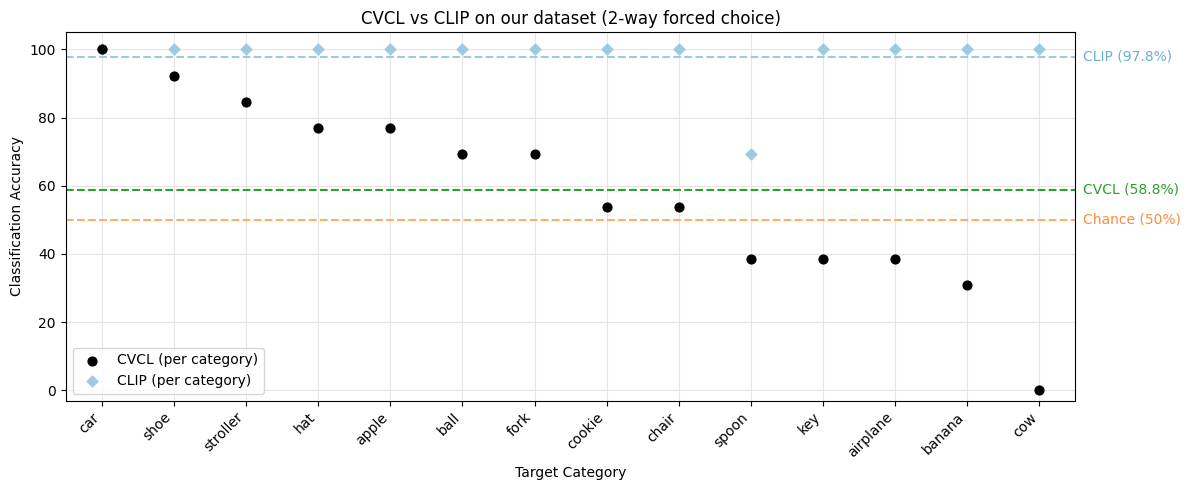

In [ ]:
# Q9 + Q10: per-object accuracy for CLIP and CVCL, then a Fig. 3A-style plot
import os, torch, clip, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from multimodal.multimodal_lit import MultiModalLitModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
image_dir = "/content/drive/MyDrive/my_images/"
image_paths = {os.path.splitext(f)[0]: os.path.join(image_dir, f)
               for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))}
labels = list(image_paths.keys())
n_trials = len(labels) - 1  # each object is tested against every other object (2-way choice)

clip_model, _ = clip.load("ViT-B/32", device=device)
clip_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

clip_acc = {}
with torch.no_grad():
    for target in labels:
        img = clip_transform(Image.open(image_paths[target]).convert("RGB")).unsqueeze(0).to(device)
        img_feat = clip_model.encode_image(img)
        correct = 0
        for distractor in labels:
            if distractor == target:
                continue
            txt_feat = clip_model.encode_text(clip.tokenize([target, distractor]).to(device))
            correct += int((img_feat @ txt_feat.T).argmax().item() == 0)
        clip_acc[target] = 100 * correct / n_trials

cvcl, preprocess = MultiModalLitModel.load_model(model_name="cvcl")
cvcl = cvcl.to(device).eval()

cvcl_acc = {}
with torch.no_grad():
    for target in labels:
        img = preprocess(Image.open(image_paths[target]).convert("RGB")).unsqueeze(0).to(device)
        img_feat = cvcl.encode_image(img)
        img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
        correct = 0
        for distractor in labels:
            if distractor == target:
                continue
            tokens, lengths = cvcl.tokenize([target, distractor])
            txt_feat = cvcl.encode_text(tokens.to(device), lengths.to(device))
            txt_feat = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
            correct += int((img_feat.float() @ txt_feat.T.float()).squeeze().argmax().item() == 0)
        cvcl_acc[target] = 100 * correct / n_trials

#results table
order = sorted(labels, key=lambda l: cvcl_acc[l], reverse=True)
print(f"{'object':<10}{'CVCL':>8}{'CLIP':>8}")
for l in order:
    print(f"{l:<10}{cvcl_acc[l]:>7.1f}%{clip_acc[l]:>7.1f}%")
cvcl_mean, clip_mean = np.mean(list(cvcl_acc.values())), np.mean(list(clip_acc.values()))
print(f"{'MEAN':<10}{cvcl_mean:>7.1f}%{clip_mean:>7.1f}%")


x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(12, 5))
ax.grid(True, color="#e6e6e6", zorder=0)
ax.scatter(x, [cvcl_acc[l] for l in order], color="black", s=40, zorder=4, label="CVCL (per category)")
ax.scatter(x, [clip_acc[l] for l in order], color="#9ecae1", marker="D", s=30, zorder=3, label="CLIP (per category)")
ax.axhline(clip_mean, ls="--", color="#9ecae1", lw=1.5)
ax.axhline(cvcl_mean, ls="--", color="#2ca02c", lw=1.5)
ax.axhline(50, ls="--", color="#fdae6b", lw=1.5)
for y, txt, c in [(clip_mean, f"CLIP ({clip_mean:.1f}%)", "#6baed6"),
                  (cvcl_mean, f"CVCL ({cvcl_mean:.1f}%)", "#2ca02c"),
                  (50, "Chance (50%)", "#fd8d3c")]:
    ax.text(len(order) - 0.4, y, txt, color=c, va="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_xlim(-0.5, len(order) - 0.5)
ax.set_ylim(-3, 105)
ax.set_xlabel("Target Category")
ax.set_ylabel("Classification Accuracy")
ax.set_title("CVCL vs CLIP on our dataset (2-way forced choice)")
ax.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()


**Question 11:**
Compare the results in your plot to those shown in Figure 3A of Vong et al. Highlight the similarities and differences between the two.

Answer:

CLIP is near ceiling in both.
CVCL is far below CLIP and only moderately above chance on average .
CVCL varies a lot between categories in both.
Shared categories often rank alike.Apple and hat are among CVCL's best in both (paper ≈ 90% and ≈ 63%). Chair is in the middle. Airplane, key and spoon are at or below chance in both.

Differences
We use a 2-way choice (target vs 1 foil, chance = 50%) while the paper uses a 4-way choice (target vs 3 foils, chance = 25%), so all our numbers are higher in absolute terms.
Some categories disagree.Shoe is 92% for us but only ≈ chance (~24%) in the paper. Cookie (54% vs ~27%) and ball (69% vs ~47%) are also higher for us.
Scale and reliability. The paper evaluates 64 categories with many images each and shows error bars over 3 training seeds. We have 14 categories,one image per category and a single model. Each of our scores comes from only 13 trials (steps of 7.7%) and has no error bars.
The paper also reports a linear-probe baseline and shuffled/random-feature controls, which we did not reproduce.

**Question 12:**
Speculate on the potential causes for the observed differences between your results and those presented in the Vong et al. paper.

Answer:

1. Different task difficulty (2-way vs 4-way). With only one foil, a random guess is right 50% of the time instead of 25%, which pushes our scores up. Foils were also chosen differently: we test every other object once, while the paper samples random foils over many trials.
2. One image per category. Each of our scores depends on a single photo, so its viewpoint, background, colour or style decides the result. That is probably why we get extreme values (car 100%, cow 0%) and why shoe scores high for us but not in the paper. The paper averages over many images per category, which gives smoother results.
3. Domain shift. CVCL was trained on egocentric head-camera frames from one child: blurry, cluttered, low-resolution views of real toys and household objects. Our images (and the paper's clean evaluation images) look different, and how far each of our images is from the child's experience varies by category.
4. The child's vocabulary and word frequency. CVCL only learns words heard in child-directed speech. Words like cow, airplane or stroller may be rare, or may mostly appear with toys, picture books or other words ("moo", "plane"). That would explain very weak or wrong embeddings for them. Frequent, concrete words with a consistent appearance (car, ball, apple) are learned better.
5. Small sample and no seeds. We have 13 trials per category, so one wrong answer changes the score by 7.7%. We also use a single CVCL checkpoint from Hugging Face, while the paper averages 3 training seeds (the error bars in Fig. 3A).
6. Preprocessing differences for CLIP. Our CLIP code uses ImageNet normalization (not CLIP's own `clip_preprocess`) and raw, unnormalized dot products instead of cosine similarity. This probably explains CLIP's unexpected 69% on spoon, where the paper's CLIP is at ~99%.